In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def ecual(img):
    resimg = img.copy()
    hist = cv2.calcHist([img], [0], None, [256], [0,256]).ravel().astype(int)
    freq_acum = np.cumsum(hist)
    N_pixeles = img.size
    FE = 255 / N_pixeles
    LUT = np.rint(FE * freq_acum).astype(np.uint8)
    filas, cols = img.shape
    for i in range(filas):
        for j in range(cols):
            resimg[i, j] = LUT[img[i, j]]

    return resimg

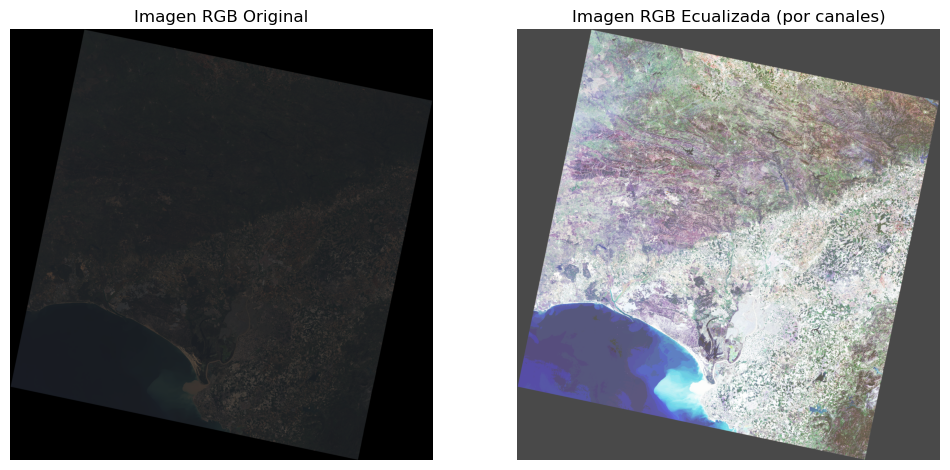

In [2]:
b = cv2.imread("RGB/Landsat_C_02-11_B.png", cv2.IMREAD_GRAYSCALE)
g = cv2.imread("RGB/Landsat_C_03-11_G.png", cv2.IMREAD_GRAYSCALE)
r = cv2.imread("RGB/Landsat_C_04-11_R.png", cv2.IMREAD_GRAYSCALE)

img_rgb = cv2.merge([b, g, r])

b_eq = ecual(b)
g_eq = ecual(g)
r_eq = ecual(r)

img_rgb_eq = cv2.merge([b_eq, g_eq, r_eq])

#Imágenes
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB))
plt.title("Imagen RGB Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img_rgb_eq, cv2.COLOR_BGR2RGB))
plt.title("Imagen RGB Ecualizada (por canales)")
plt.axis("off")
plt.show()